Ссылка на clearml с логами обучения: [clearml](https://app.clear.ml/projects/d6209850b8fb417bb10decb4dfaccfd8/tasks/2d60d8e25cc9405587bd1dbd8659c5f7/scalars?columns=selected&columns=type&columns=name&columns=tags&columns=status&columns=project.name&columns=users&columns=started&columns=last_update&columns=last_iteration&columns=parent.name&order=-last_update)

API ключи clearml намеренно удалены

In [1]:
!pip install -q clearml ultralytics

In [ ]:
import os
from clearml import Task
from ultralytics import YOLO

os.environ["CLEARML_NO_DEFAULT_CONFIG"] = "1"
os.environ["CLEARML_WEB_HOST"] = "https://app.clear.ml"
os.environ["CLEARML_API_HOST"] = "https://api.clear.ml"
os.environ["CLEARML_FILES_HOST"] = "https://files.clear.ml"
os.environ["CLEARML_API_ACCESS_KEY"] = ""
os.environ["CLEARML_API_SECRET_KEY"] = ""

In [3]:
task = Task.init(
    project_name="CeramicNet",
    task_name="misha-yolo26s",
    reuse_last_task_id=False
)

params = {
    "model_name": "yolo26s.pt",
    "data_path": "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/data.yaml",
    "epochs": 50,
    "batch_size": 16,
    "imgsz": 640,
    "optimizer": "auto",
    "lr0": 0.01,
    "close_mosaic": 10,
    "device": 0
}
task.connect(params)

model = YOLO(params["model_name"])

results = model.train(
    data=params["data_path"],
    epochs=params["epochs"],
    batch=params["batch_size"],
    imgsz=params["imgsz"],
    verbose=False,
    optimizer=params["optimizer"],
    lr0=params["lr0"],
    close_mosaic=params["close_mosaic"],
    device=params["device"],
    workers=4,
    plots=True
)

metrics = model.val()

task.close()

ClearML Task: created new task id=2d60d8e25cc9405587bd1dbd8659c5f7
2026-10-21 17:31:59,516 - clearml.Repository Detection - WARNING - Jupyter Notebook auto-logging failed, could not access: /kaggle/working/__notebook_source__.ipynb
ClearML results page: https://app.clear.ml/projects/d6209850b8fb417bb10decb4dfaccfd8/tasks/2d60d8e25cc9405587bd1dbd8659c5f7/output/log
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning:

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.



       2/50       5.7G      1.323      3.042    0.01325         19        640: 100% ━━━━━━━━━━━━ 13/13 4.5it/s 2.9s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.4it/s 0.4s0.9s
                   all         51         51      0.569      0.647       0.61      0.256

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      5.71G      1.569      2.272    0.01606         21        640: 100% ━━━━━━━━━━━━ 13/13 4.6it/s 2.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.7it/s 0.4s0.8s
                   all         51         51      0.304      0.294      0.207     0.0494

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      5.71G      1.499      2.006    0.01505         21        640: 100% ━━━━━━━━━━━━ 13/13 4.5it/s 2.9s0.2s
                 Class     Images  Instances  

███████████████████████████████ 100% | 19.37/19.37 MB [00:00<00:00, 68.79MB/s]: 


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 328.3±50.8 MB/s, size: 204.9 KB)
val: Scanning /kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/labels/val... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 793.7it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s0.8s
                   all         51         51      0.991      0.922      0.968       0.71
Speed: 6.0ms preprocess, 14.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val



0: 640x640 1 kleimo, 10.7ms
1: 640x640 1 kleimo, 10.7ms
2: 640x640 1 kleimo, 10.7ms
3: 640x640 1 kleimo, 10.7ms
4: 640x640 1 kleimo, 10.7ms
5: 640x640 1 kleimo, 10.7ms
6: 640x640 1 kleimo, 10.7ms
7: 640x640 1 kleimo, 10.7ms
8: 640x640 1 kleimo, 10.7ms
9: 640x640 1 kleimo, 10.7ms
Speed: 1.7ms preprocess, 10.7ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


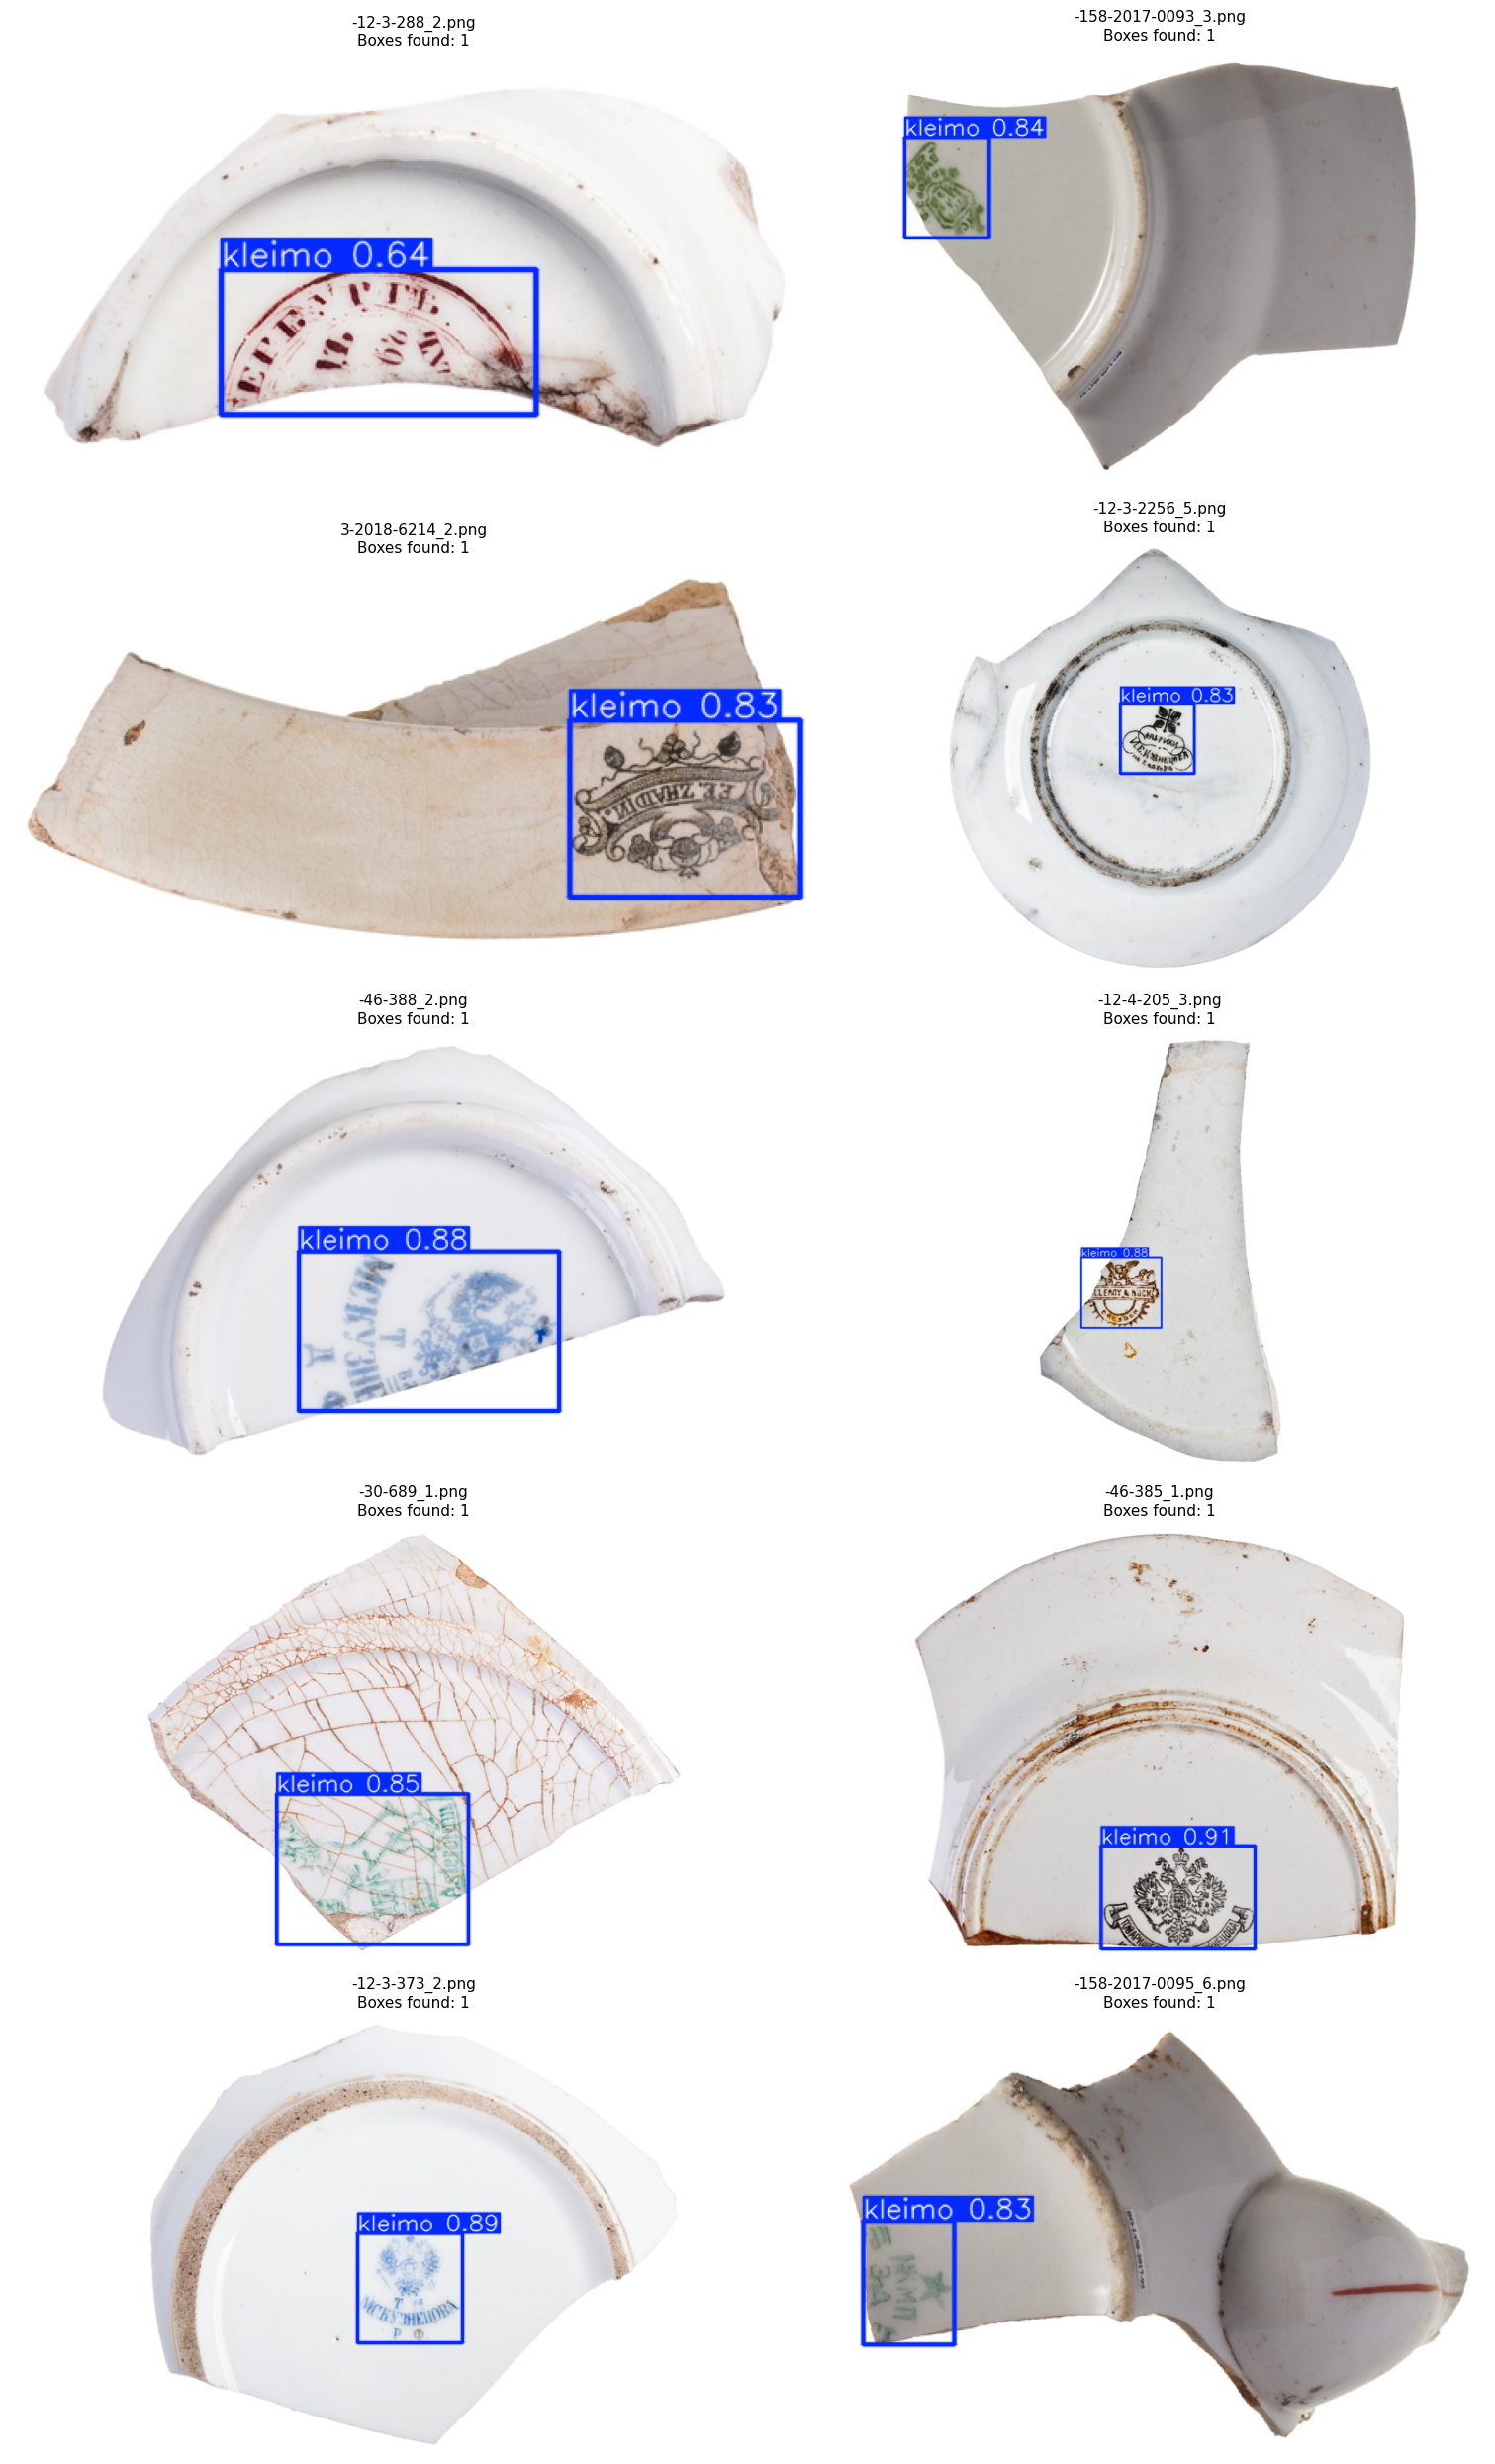

In [5]:
import random
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

val_dir = Path("/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/images/val")
all_val_images = list(val_dir.glob("*.png")) + list(val_dir.glob("*.jpg"))
sample_images = [str(p) for p in random.sample(all_val_images, min(10, len(all_val_images)))]

preds = model.predict(sample_images, conf=0.25, imgsz=640)

fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for idx, (img_path, result) in enumerate(zip(sample_images, preds)):
    annotated_img = result.plot()
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(annotated_img_rgb)
    axes[idx].set_title(f"{Path(img_path).name}\nBoxes found: {len(result.boxes)}", fontsize=11)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()


0: 640x640 1 kleimo, 16.1ms
1: 640x640 1 kleimo, 16.1ms
2: 640x640 1 kleimo, 16.1ms
3: 640x640 1 kleimo, 16.1ms
Speed: 1.9ms preprocess, 16.1ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


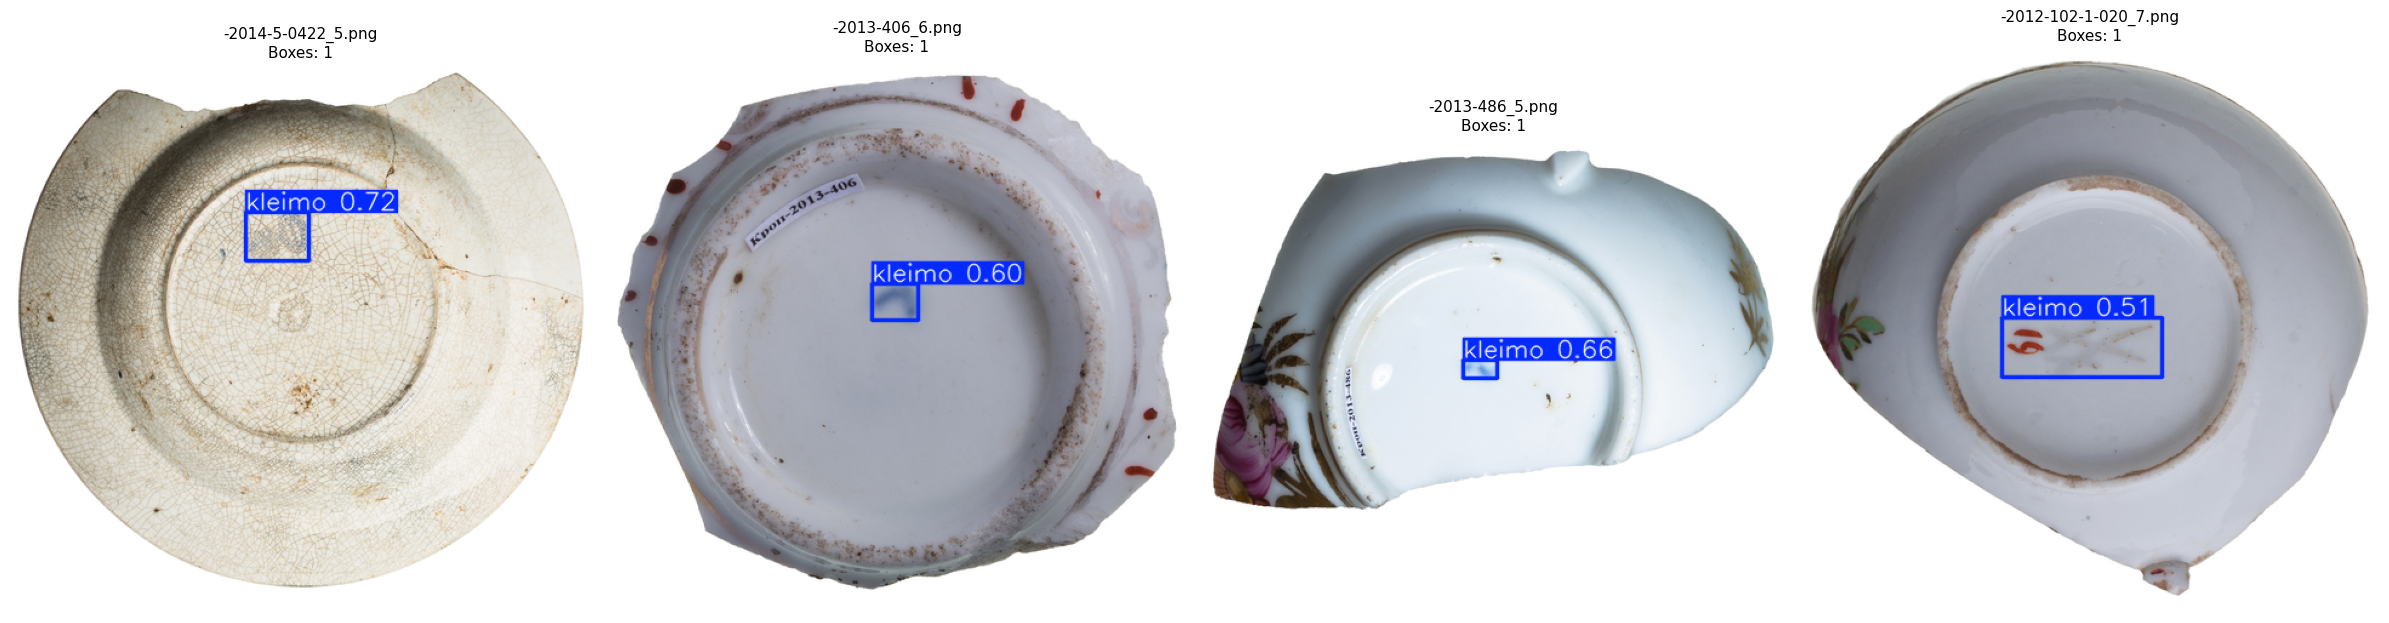

In [11]:
image_paths = [
    "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/images/train/-2014-5-0422_5.png",
    "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/images/train/-2013-406_6.png",
    "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/images/train/-2013-486_5.png",
    "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/images/train/-2012-102-1-020_7.png"
]

preds = model.predict(image_paths, conf=0.25, imgsz=640)

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

for idx, (img_path, result) in enumerate(zip(image_paths, preds)):
    annotated_img = result.plot()
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(annotated_img_rgb)
    axes[idx].set_title(f"{Path(img_path).name}\nBoxes: {len(result.boxes)}", fontsize=11)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [15]:
import torch

torch.save({"model": model.model}, "/kaggle/working/ceramic_yolo26s_best.pt")